In [103]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [132]:
# Импорт библиотек для машинного обучения и обработки текста
import pandas as pd
import numpy as np
import random
import seaborn as sns

# Импорт sklearn для классических алгоритмов ML
from sklearn.model_selection import train_test_split, StratifiedKFold  # разделение данных и кросс-валидация
from sklearn.dummy import DummyClassifier  # наивный классификатор для бейслайна
from sklearn.compose import ColumnTransformer  # трансформация разных столбцов по-разному
from sklearn.pipeline import Pipeline  # создание пайплайнов обработки
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer  # векторизация текста
from sklearn.linear_model import LogisticRegression  # логистическая регрессия
from sklearn.tree import DecisionTreeClassifier  # дерево решений
from sklearn.ensemble import RandomForestClassifier  # случайный лес
from sklearn.base import clone  # клонирование моделей
from lightgbm import LGBMClassifier  # градиентный бустинг
from sklearn.feature_selection import SelectKBest, f_classif

# Пользовательские модули
from nlp import * 
from helper import *
from plots import *


In [105]:
SEED = 42 
np.random.seed(SEED)
random.seed(SEED)

In [106]:
df = pd.read_csv("IMDB Dataset.csv")

5. Препроцессинг данных

5.1 Общие преобразования

In [107]:
# Создаем копию данных для предобработки
df_preprocessed = df.copy()

# Очищаем отзывы от HTML мусора
df_preprocessed["review_clean"] = df_preprocessed["review"].apply(strip_html)

# Убираем дубликаты из датасета
df_preprocessed = df_preprocessed.drop_duplicates()

# Преобразуем таргет в числовой формат
df_preprocessed["sentiment"] = df_preprocessed["sentiment"].map({"positive": 1, "negative": 0})

Токенизацию будем делать внутри пайплайна внутри CountVectorizer, это проще 

In [108]:
# Разделяем данные на признаки и таргет 
X, y = df_preprocessed["review_clean"], df_preprocessed["sentiment"]

6. Построение baseline

In [109]:
# Определяем набор моделей для сравнения 

models = [
    ('DummyClassifier', DummyClassifier(random_state=SEED, strategy='most_frequent')),
    ('LogisticRegression', LogisticRegression(random_state=SEED, max_iter=1000, solver='liblinear')),
    ('DecisionTreeClassifier', DecisionTreeClassifier(random_state=SEED, max_depth=4)),
    ('RandomForestClassifier', RandomForestClassifier(random_state=SEED)),
    ('LGBMClassifier', LGBMClassifier(random_state=SEED, verbose=-1))
]

In [110]:
# Делаем кросс-валидацию с 5 фолдами, используем stratified чтобы в каждом фолде было одинаковое соотношение классов

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

6.1 CountVectorizer 

6.1.1 Без очистки токенов

In [111]:
# Создаем пайплайн для векторизации текстов

count_vectorizer_preprocessor = Pipeline([
    ('vectorizer', CountVectorizer(dtype=np.float32)) # Преобразуем int в float , чтобы бустинг не падал
])

In [112]:
scoring = ['accuracy', 'f1', 'roc_auc']
count_vectorizer_metrics = evaluate_models_cv(models, X, y, count_vectorizer_preprocessor, cv, scoring)

/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site

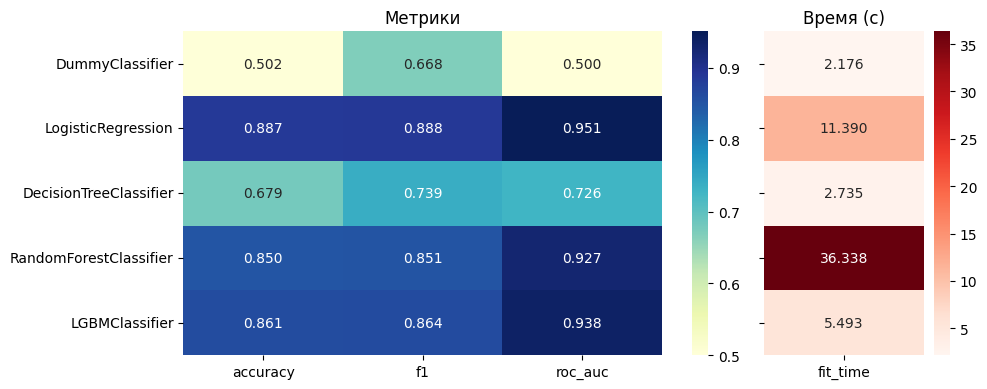

In [127]:
#sns.heatmap(count_vectorizer_metrics, annot=True, cmap="YlGnBu", fmt=".3f")

plot_metrics_with_time(count_vectorizer_metrics)

Теперь нужно вытащить самые важные признаки

In [114]:
logreg_pipe = Pipeline([
    ("preprocessor", count_vectorizer_preprocessor),
    ("model", LogisticRegression(random_state=SEED, max_iter=1000, solver="liblinear")),
])
logreg_pipe.fit(X, y)


Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('vectorizer',
                                  CountVectorizer(dtype=<class 'numpy.float32'>))])),
                ('model',
                 LogisticRegression(max_iter=1000, random_state=42,
                                    solver='liblinear'))])

<Axes: >

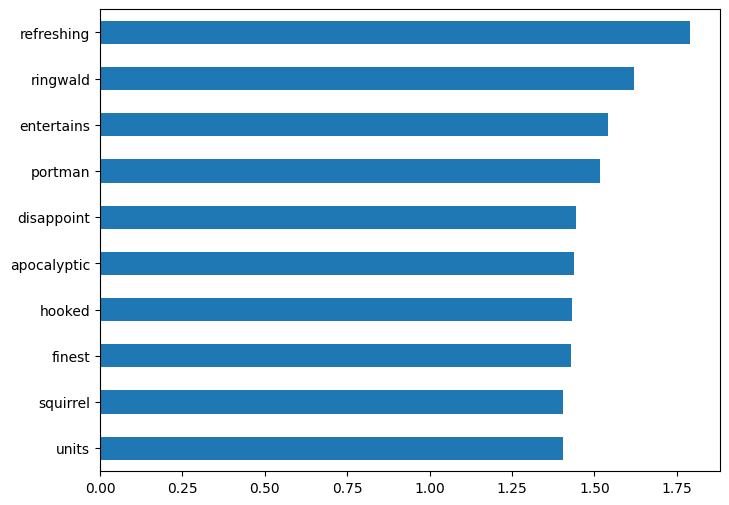

In [115]:
feature_names =  logreg_pipe.named_steps["preprocessor"].named_steps["vectorizer"].get_feature_names_out()

coefs = logreg_pipe.named_steps["model"].coef_[0]

importance = pd.Series(coefs, index=feature_names).sort_values()

importance.tail(10).plot(kind="barh", figsize=(8, 6)) # самые положительные 

<Axes: >

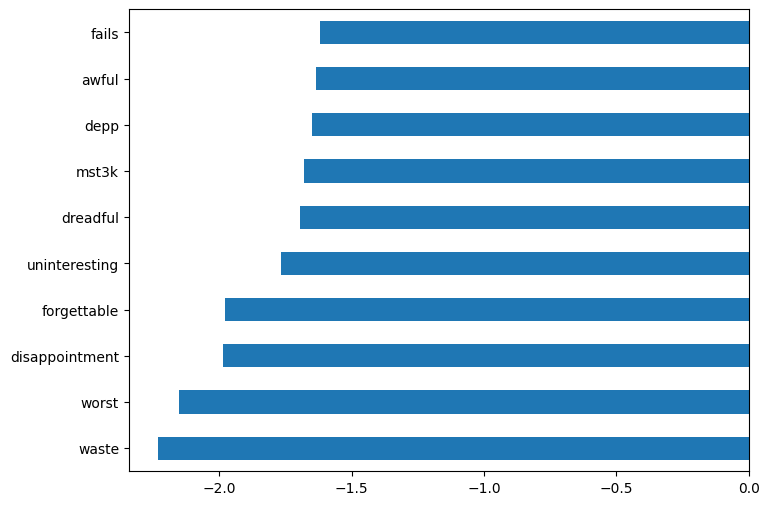

In [116]:
importance.head(10).plot(kind="barh", figsize=(8, 6)) # самые отрицательные

Это для одной функции, но лучше обобщить для всех моделей сразу

DummyClassifier нет фичей


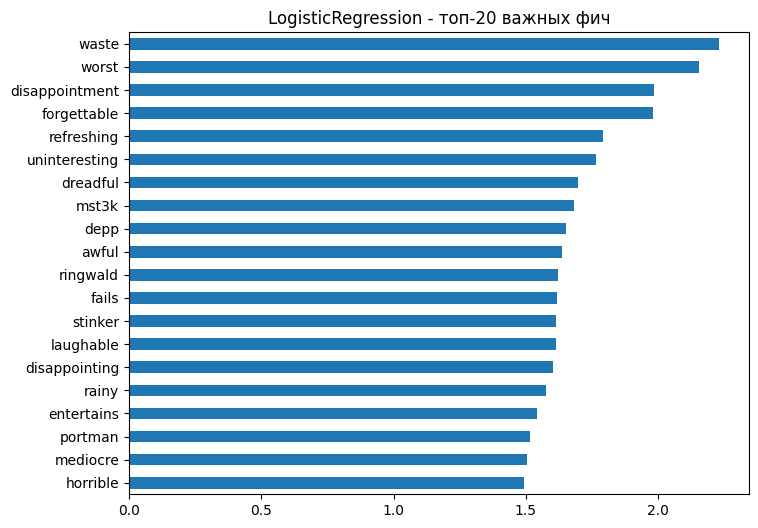

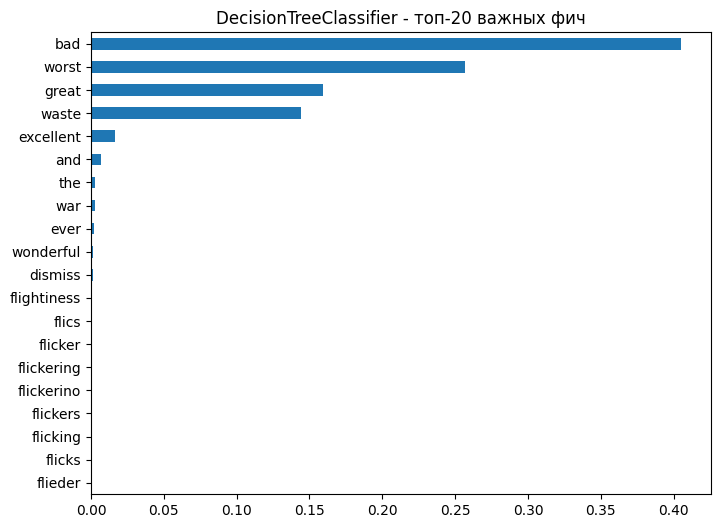

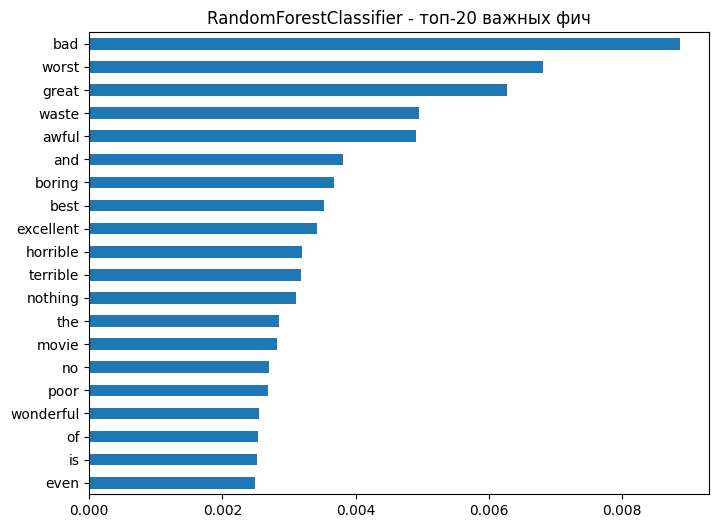

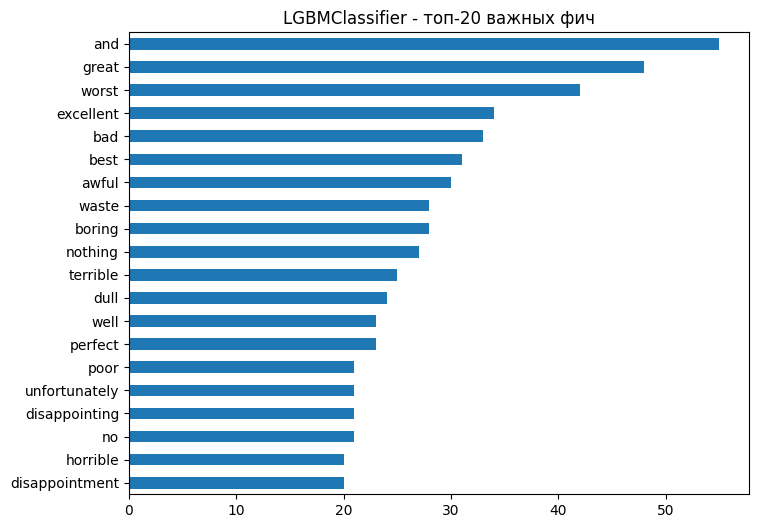

In [117]:
for name, model in models:
    pipe = Pipeline([
        ("preprocessor", count_vectorizer_preprocessor),
        ("model", clone(model))
    ])
    pipe.fit(X, y)
    plots_importances(pipe, name)

Вывод:

По метрикам видно, что логрег лучше всех остальных моделей. Дамми классификатор и одиночное дерево худшие по качеству. 

По важности признакам видно, что логрег ровнее всех отдает важность признакам, у остальных моделей есть сильная доминация конкретных признаков.

Бустинг вообще самой важной фичей сделал стоп-слово. Поэтому следующим шагом является удалить стоп-слова.

6.1.2 Удалим стоп-слова

In [118]:
count_vectorizer_preprocessor_clean = Pipeline([
    ('vectorizer', CountVectorizer(stop_words="english", dtype=np.float32)) # Преобразуем int в float , чтобы бустинг не падал
])

scoring = ['accuracy', 'f1', 'roc_auc']
count_vectorizer_metrics_clean = evaluate_models_cv(models, X, y, count_vectorizer_preprocessor_clean, cv, scoring)

/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site

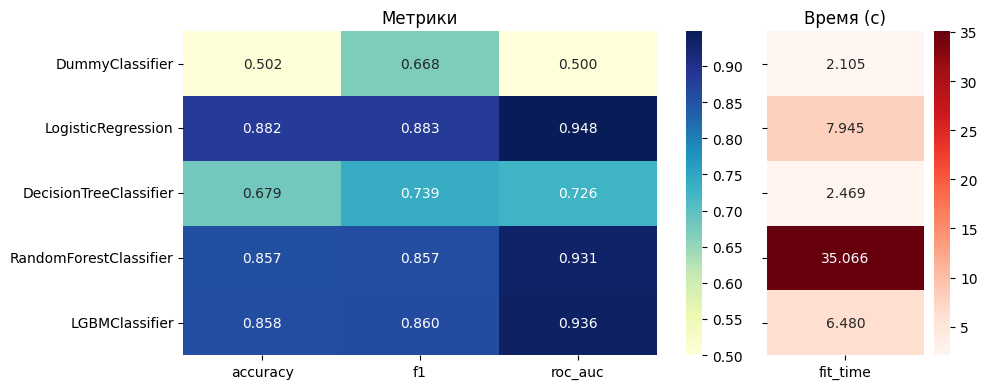

In [128]:
#sns.heatmap(count_vectorizer_metrics_clean, annot=True, cmap="YlGnBu", fmt=".3f")

plot_metrics_with_time(count_vectorizer_metrics_clean)

DummyClassifier нет фичей


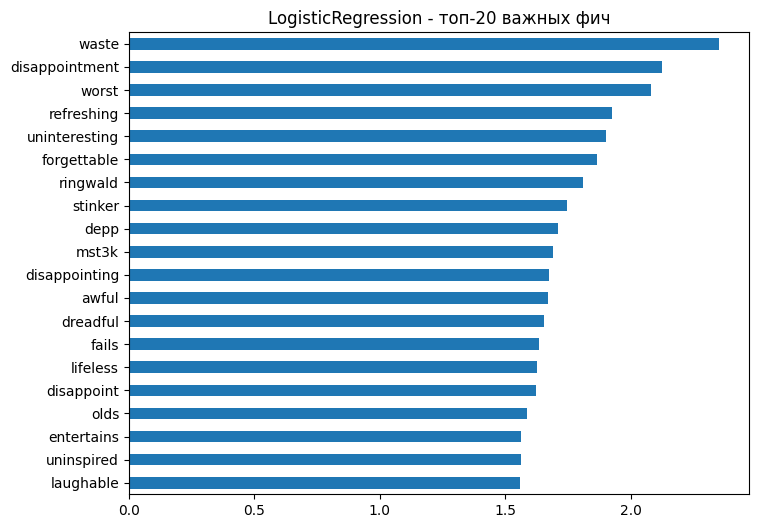

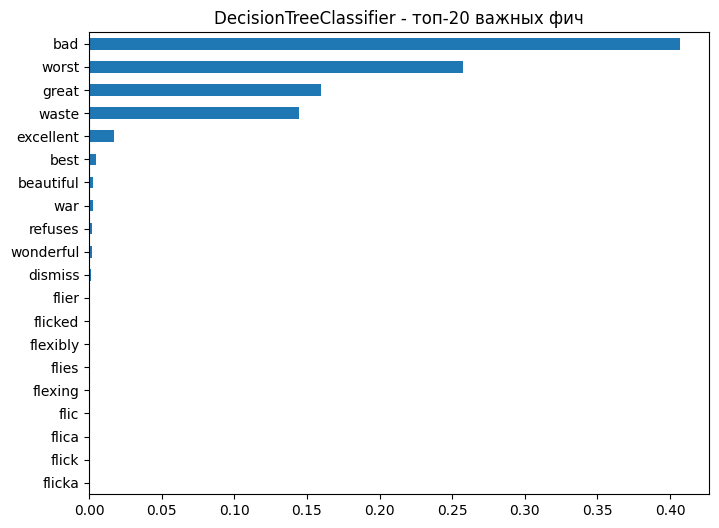

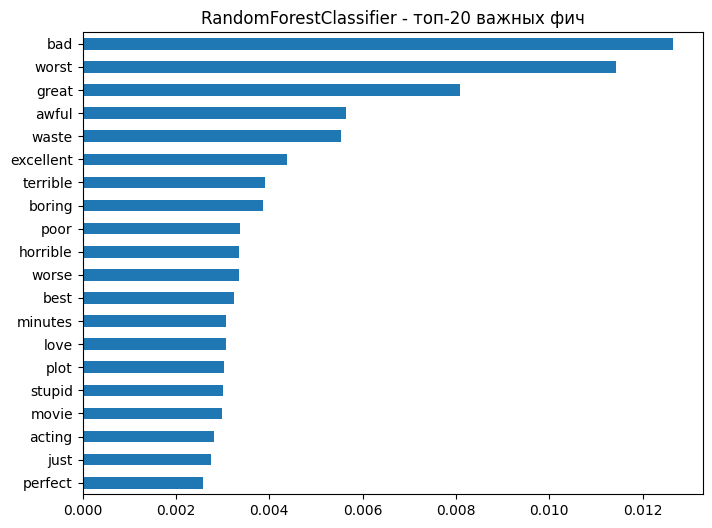

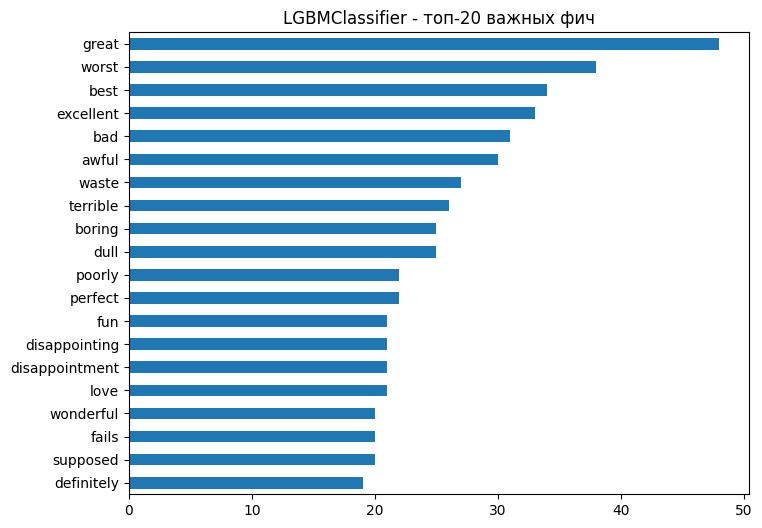

In [120]:
for name, model in models:
    pipe = Pipeline([
        ("preprocessor", count_vectorizer_preprocessor_clean),
        ("model", clone(model))
    ])
    pipe.fit(X, y)
    plots_importances(pipe, name)

Теперь сравним метрики со стоп словами и без стоп слов

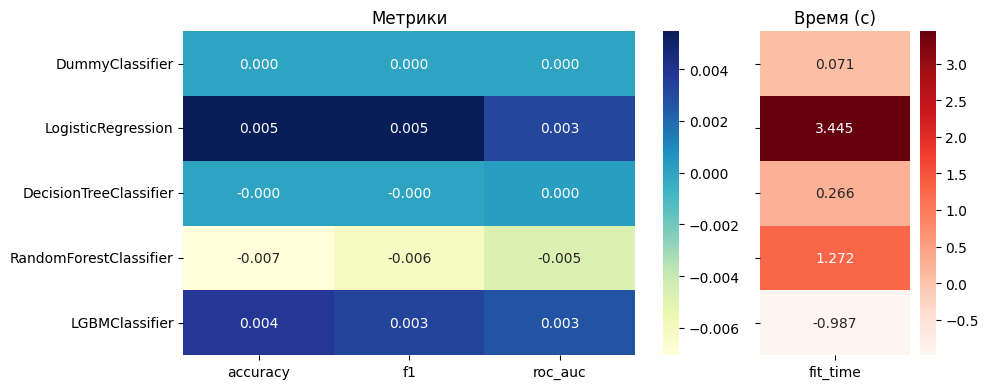

In [129]:
delta = count_vectorizer_metrics - count_vectorizer_metrics_clean
plot_metrics_with_time(delta)

Вывод по удалению стоп слов: 

Удаление стоп слов не сильно помогло, все метрики в пределах шума, устойчивого прироста нет. 

6.1.3 Топ 5000 важных токенов

/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site

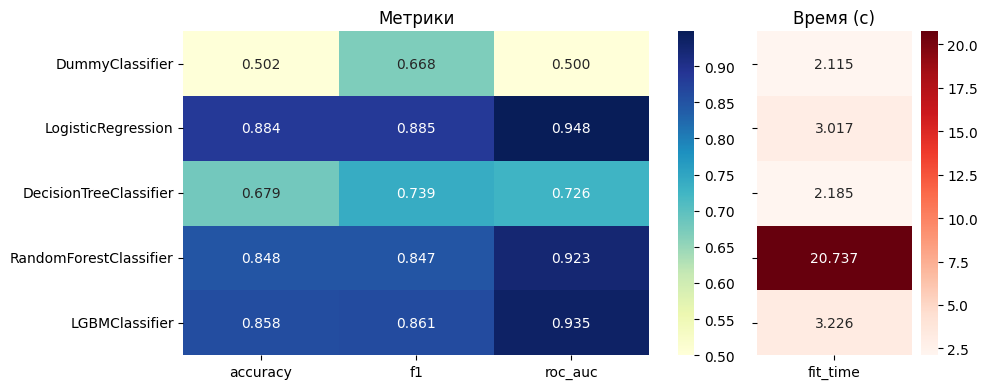

In [135]:
count_vectorizer_preprocessor_top = Pipeline([
    ('vectorizer', CountVectorizer(stop_words="english", dtype=np.float32)),  # Преобразуем int в float , чтобы бустинг не падал
    ('selector', SelectKBest(score_func = f_classif,  k=5000))
     
])

scoring = ['accuracy', 'f1', 'roc_auc']
count_vectorizer_metrics_top = evaluate_models_cv(models, X, y, count_vectorizer_preprocessor_top, cv, scoring)

plot_metrics_with_time(count_vectorizer_metrics_top)

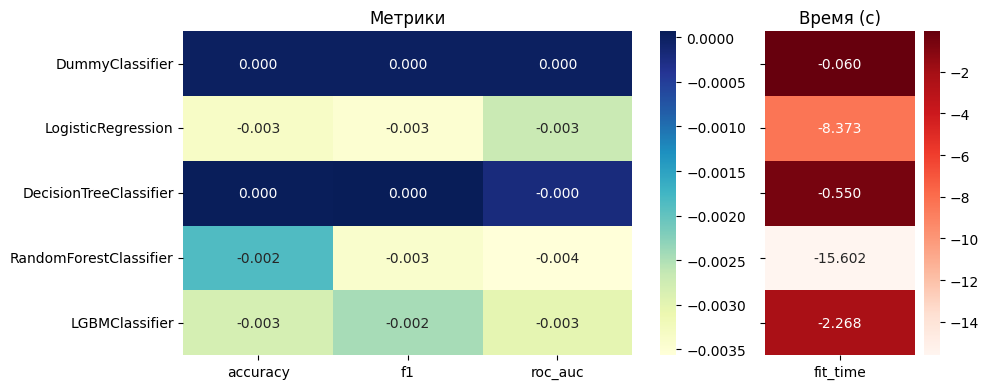

In [136]:
delta = count_vectorizer_metrics_top - count_vectorizer_metrics
plot_metrics_with_time(delta)

Вывод: 

Если сравнивать метрики и время выполнения с полным словарем и с топ 100 и топ 5000 токенов, то при 5000 токенов метрики падают на уровне шума, а время обучения уменьшается так же на уровне шума. При 100 токенах у логрега, случайного леса и бустинга метрики падают на 0.03-0.05 , а время обучения заметно не сокращается. Поэтому будем использовать полный словарь. 

6.2 TF-IDF Vectorizer

6.2.1 Без очистки токенов 

In [ ]:
# Создаем пайплайн для TF-IDF векторизации
TFIDF_vectorizer_preprocessor = Pipeline([
    ('vectorizer', TfidfVectorizer(dtype=np.float32)) # Преобразуем int в float , чтобы бустинг не падал
])

/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site

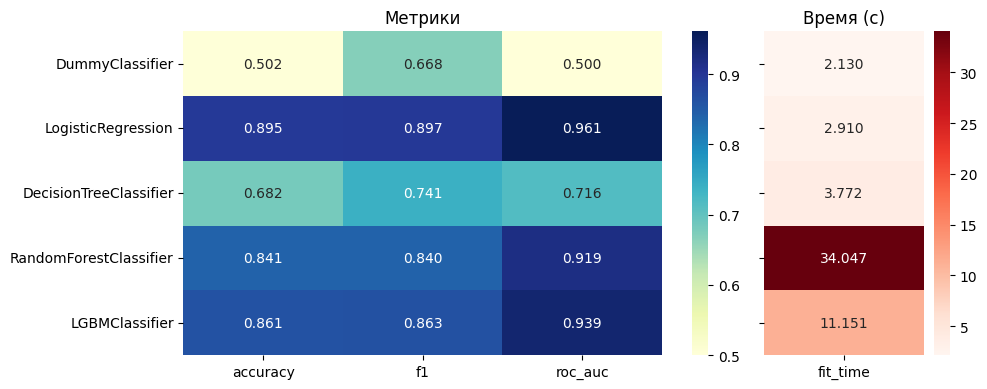

In [139]:
scoring = ['accuracy', 'f1', 'roc_auc']
TFIDF_vectorizer_metrics = evaluate_models_cv(models, X, y, TFIDF_vectorizer_preprocessor, cv, scoring)

plot_metrics_with_time(TFIDF_vectorizer_metrics)

DummyClassifier нет фичей


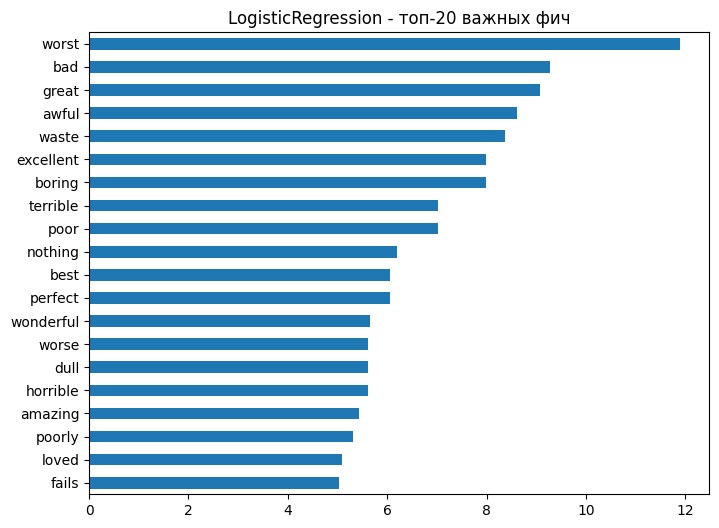

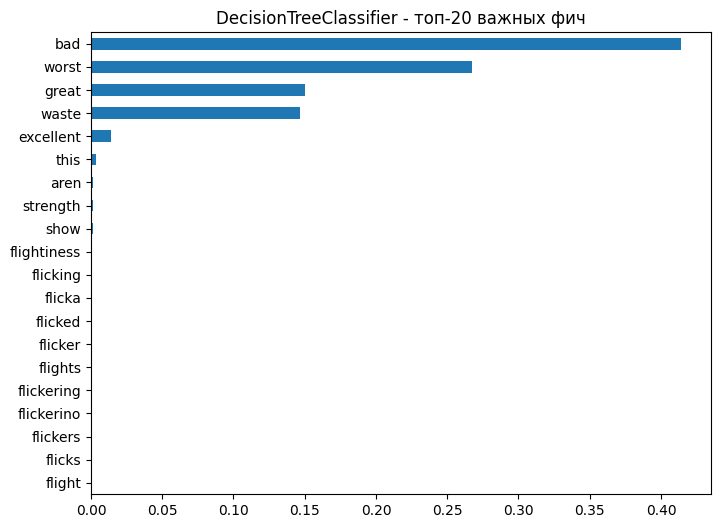

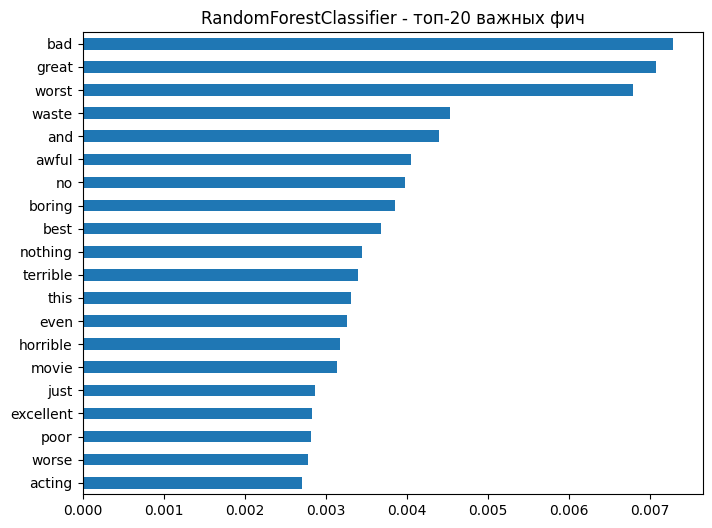

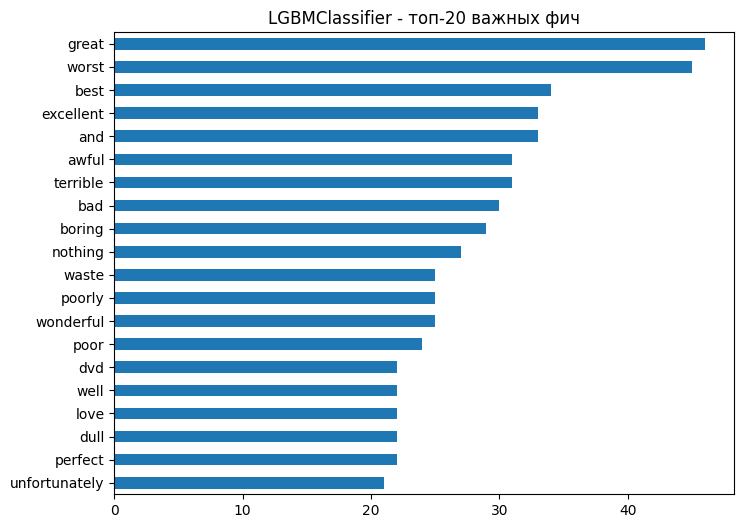

In [140]:
for name, model in models:
    pipe = Pipeline([
        ("preprocessor", TFIDF_vectorizer_preprocessor),
        ("model", clone(model))
    ])
    pipe.fit(X, y)
    plots_importances(pipe, name)

6.1.2 Удаление стоп слов

In [143]:
# Создаем пайплайн для TF-IDF векторизации
TFIDF_vectorizer_preprocessor_clean = Pipeline([
    ('vectorizer', TfidfVectorizer(stop_words="english", dtype=np.float32)) # Преобразуем int в float , чтобы бустинг не падал
])

/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задача_NLP_классификация/.venv/lib/python3.11/site

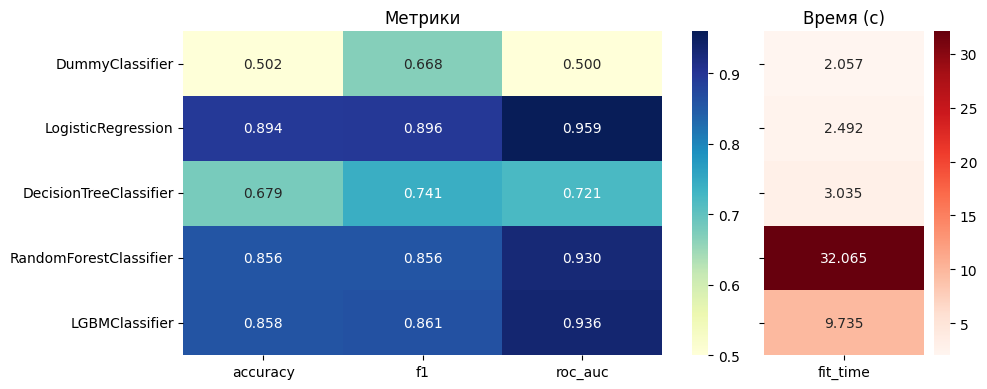

In [144]:
scoring = ['accuracy', 'f1', 'roc_auc']
TFIDF_vectorizer_metrics_clean = evaluate_models_cv(models, X, y, TFIDF_vectorizer_preprocessor_clean, cv, scoring)

plot_metrics_with_time(TFIDF_vectorizer_metrics_clean)

DummyClassifier нет фичей


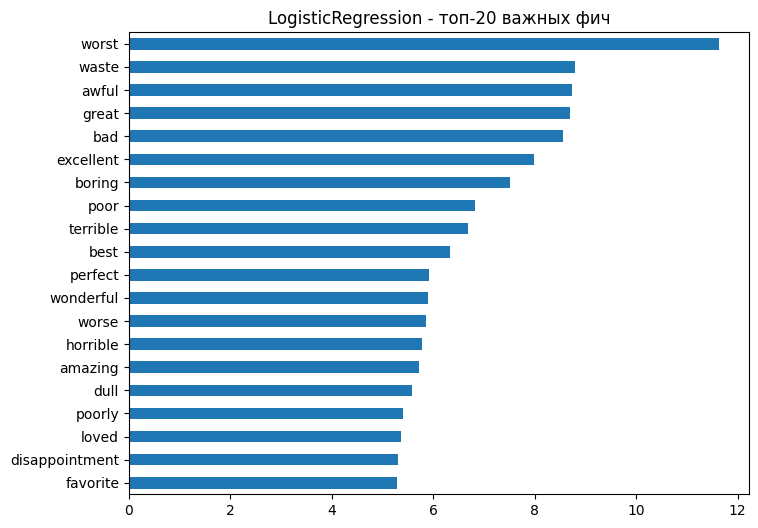

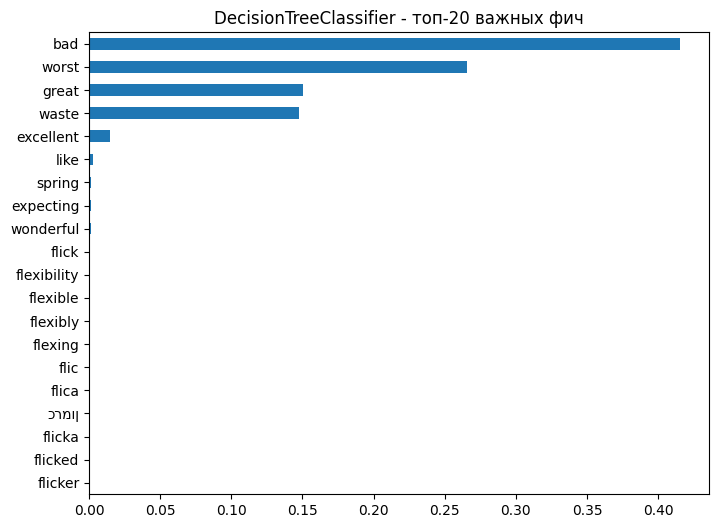

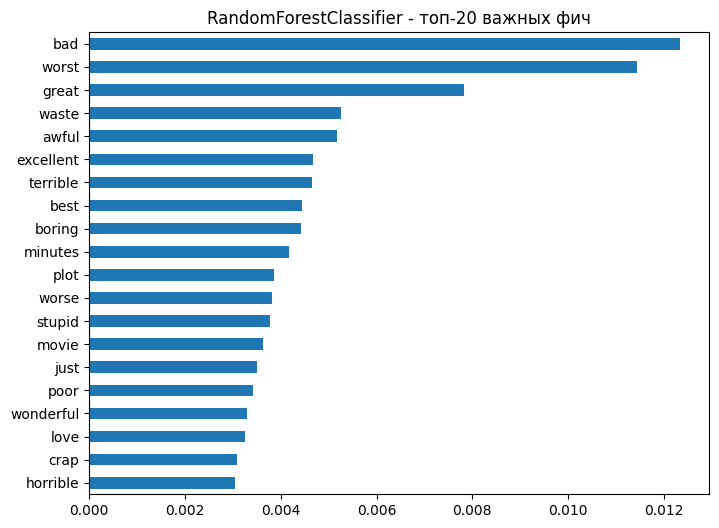

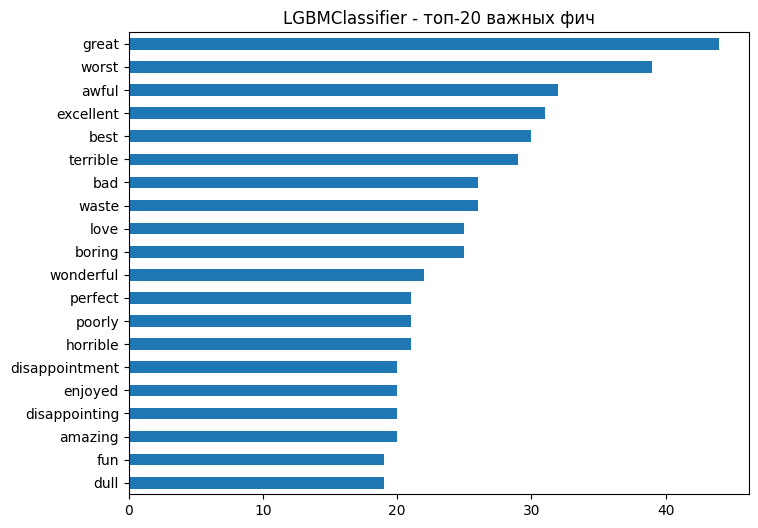

In [145]:
for name, model in models:
    pipe = Pipeline([
        ("preprocessor", TFIDF_vectorizer_preprocessor_clean),
        ("model", clone(model))
    ])
    pipe.fit(X, y)
    plots_importances(pipe, name)

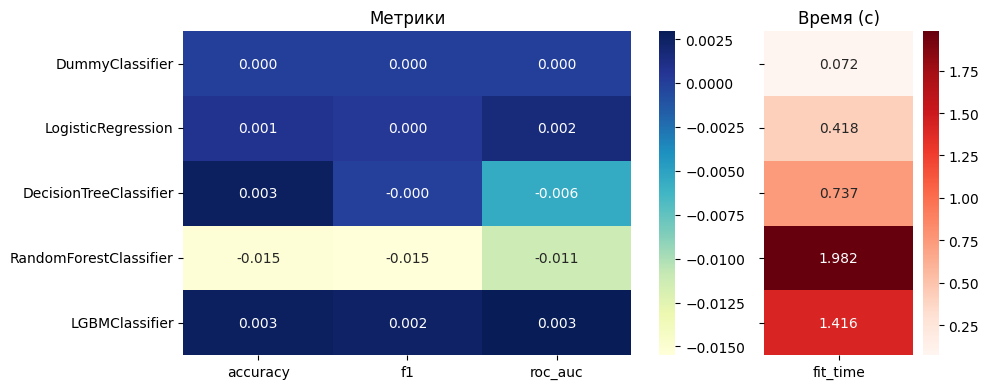

In [151]:
delta = TFIDF_vectorizer_metrics - TFIDF_vectorizer_metrics_clean
plot_metrics_with_time(delta)

Удаление стоп слов не дало существенного прироста метрикам, а наоборот у всех моделей кроме одиночного дерева. Время обучения моделей так же не ускорилось, все на уровне шума

Теперь сравним BOW и TF-IDF на неочищенных данных

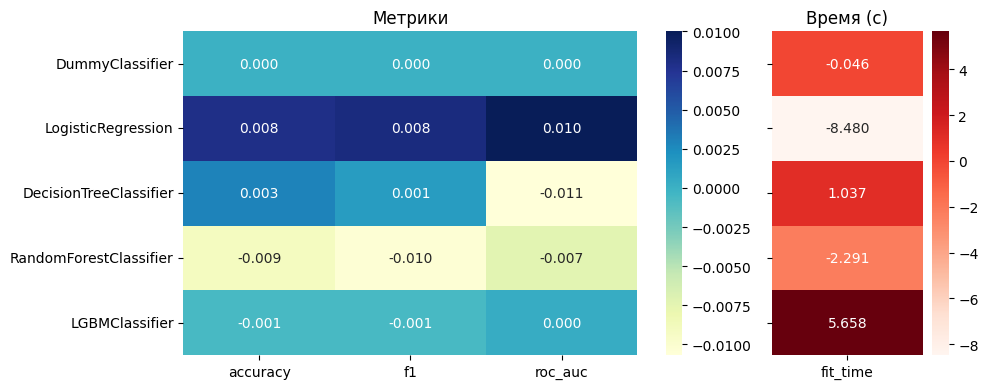

In [152]:
delta = TFIDF_vectorizer_metrics - count_vectorizer_metrics

plot_metrics_with_time(delta)

Вывод: 

Лучший результат показал TF-IDF без удаления стоп слов, удаление стоп слов ничего не дало для TF-IDF, так как он уже сам глушит самые частые слова в корпусе
